In [1]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import bootstrap

In [2]:
def ranked_probability_scores(observations, predictions):
    
    N = len(observations)
    rps = np.zeros(N)
    
    for i in range(N):
        
        observation_prob = np.array([0,0,0])
        observation_prob[observations[i]] = 1
            
        rps[i] = 1/2*( (np.cumsum(predictions[i])-np.cumsum(observation_prob))**2 ).sum()

    return rps

In [3]:
df_features = pd.read_csv('features/features_EE_week3_new.csv')
df_target = pd.read_csv('targets/eastern_temperature_terc_cat_new.csv')

In [4]:
df_features['time'] = pd.to_datetime(df_features['time'])
df_features = df_features.set_index('time')

df_target['time'] = pd.to_datetime(df_target['time'])
df_target = df_target.set_index('time')

In [5]:
y_train = df_target[df_target.index < "2010-07"].values[:,0]
y_test = df_target[df_target.index >= "2010-07"].values[:,0]

In [6]:
drop = ['MJO_phase', 'nino3.4_index', 'sea_ice_arctic', 'sea_ice_baka', 'soil_moist_upper', 'soil_moist_lower', 'snow_depth', 'u10_60N']
df_features_sel = df_features.drop(columns=drop)
len(df_features_sel.columns)

1

In [7]:
X_train = df_features_sel[df_features_sel.index < "2010-07"].values
X_test = df_features_sel[df_features_sel.index >= "2010-07"].values

In [8]:
classifier = RandomForestClassifier(n_estimators=1000, criterion='gini', max_depth=None, min_samples_leaf=1100, random_state=42)
classifier.fit(X_train, y_train)

y_pred = classifier.predict_proba(X_test)
rps = ranked_probability_scores(y_test, y_pred)

y_climpred = 1/3*np.ones((15*84, 3))
rps_clim = ranked_probability_scores(y_test, y_climpred)

print(rps.mean())
print(rps_clim.mean())

0.21512850362281466
0.21600529100529103


In [9]:
rpss = 100*(1-rps.mean()/rps_clim.mean())
print(rpss)

0.4059101415506028


In [2]:
rps_valid = 0.2216816189584887
rpss_valid = 100*(1-rps_valid/2*9)
print(rpss_valid)

0.2432714686800841


In [3]:
rps_valid_clim = 0.22372728884237786
rpss_valid_unbiased = 100*(1-rps_valid/rps_valid_clim)
print(rpss_valid_unbiased)

0.9143586794771341


In [11]:
rps_ann = rps.reshape((15,84)).mean(axis=1)
rps_clim_ann = rps_clim.reshape((15,84)).mean(axis=1)

In [12]:
def skill_score(score, ref_score, axis=-1):
    mean = np.mean(score, axis=axis)
    mean_ref = np.mean(ref_score, axis=axis)
    return 1 - mean/mean_ref

In [13]:
skill_score(rps_ann, rps_clim_ann)

np.float64(0.004059101415506139)

In [14]:
res = bootstrap((rps_ann, rps_clim_ann), skill_score, paired=True, confidence_level=0.90, rng=42)

In [15]:
res.confidence_interval

ConfidenceInterval(low=np.float64(-0.01945922110483351), high=np.float64(0.028901768543125456))

0.0008767873824763465


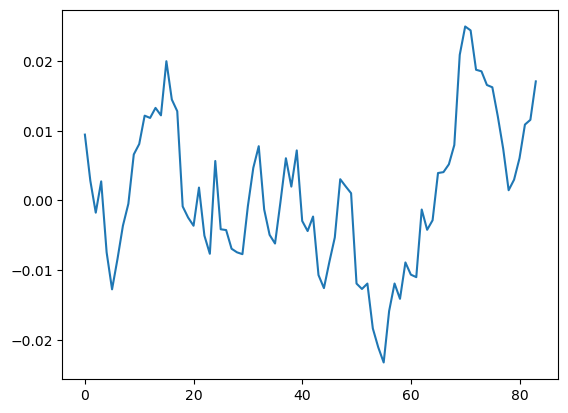

In [16]:
drps_cyc = rps_clim.reshape((15,84)).mean(axis=0) - rps.reshape((15,84)).mean(axis=0)
print(drps_cyc.mean())
plt.plot(drps_cyc)